<a href="https://colab.research.google.com/github/jisjeeson/ICT_ASSESSMENTS/blob/main/CASE_STUDY_JIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [ ]:
# Load the dataset

df = pd.read_csv("/content/House_Pricing.csv")

# Display first 5 rows

df.head()

In [ ]:
df.shape

In [ ]:
#basic information

df.info()

In [ ]:
# Statistical summary of numerical columns

df.describe()

In [ ]:
# Check missing values

df.isnull().sum()

In [ ]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Fill numerical missing values with median
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

In [ ]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include="object").columns

# Fill categorical missing values with mode
for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [ ]:
df.isnull().sum()

In [ ]:
# Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

In [ ]:
df["Date House was Sold"] = pd.to_datetime(
    df["Date House was Sold"],
    errors="coerce"
)

In [ ]:
df["Date House was Sold"].head()

In [ ]:
df["Sale_Year"] = df["Date House was Sold"].dt.year
df["Sale_Month"] = df["Date House was Sold"].dt.month
df["Sale_Day"] = df["Date House was Sold"].dt.day

In [ ]:
df.drop("Date House was Sold", axis=1, inplace=True)

In [ ]:
df["Waterfront View"] = df["Waterfront View"].map({
    "Yes": 1,
    "No": 0
})

In [ ]:
visit_mapping = {
    "Once": 1,
    "Twice": 2,
    "Thrice": 3,
    "Four": 4
}

df["No of Times Visited"] = df["No of Times Visited"].map(visit_mapping)

In [ ]:
condition_mapping = {
    "Bad": 1,
    "Fair": 2,
    "Okay": 3,
    "Good": 4,
    "Excellent": 5
}

df["Condition of the House"] = df["Condition of the House"].map(
    condition_mapping
)

In [ ]:
df.head()

In [ ]:
df.columns

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Sale Price"], bins=50, kde=True)

plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Sale Price"])

plt.title("Boxplot of Sale Price")
plt.xlabel("Sale Price")

plt.show()

Conclusion
— Sale Price Distribution
The distribution of Sale Price is highly right-skewed, with most houses having relatively lower prices. A small number of houses have substantially higher sale prices.

— Sale Price Boxplot
The boxplot shows several high-value outliers in Sale Price. These observations indicate considerable variation in house prices and will be considered during model building.

In [ ]:
# Calculate correlation matrix

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Select the chosen features

selected_features = [
    "No of Bedrooms",
    "No of Bathrooms",
    "Flat Area (in Sqft)",
    "Overall Grade",
    "Area of the House from Basement (in Sqft)"
]

X = df[selected_features]
y = df["Sale Price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

In [ ]:
# Outlier handling using IQR clipping for selected features

for column in selected_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = df[column].clip(lower_bound, upper_bound)

print("Outlier clipping completed for selected features.")

In [ ]:
from sklearn.model_selection import train_test_split

X = df[selected_features]
y = df["Sale Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

## MODELS

In [ ]:
#LR
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully.")

In [ ]:
# Predict Sale Price

y_pred_lr = lr_model.predict(X_test_scaled)

print(y_pred_lr[:5])

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("-------------------------")
print("MAE :", mae_lr)
print("MSE :", mse_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_lr, alpha=0.5)

# Perfect prediction line
min_value = min(y_test.min(), y_pred_lr.min())
max_value = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - Linear Regression")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#KNN Regression

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# Create the model
knn_model = KNeighborsRegressor(
    n_neighbors=5
)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN Regression model trained successfully.")

In [ ]:
y_pred_knn = knn_model.predict(X_test_scaled)

print(y_pred_knn[:5])

In [ ]:
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN Regression")
print("-------------------------")
print("MAE :", mae_knn)
print("MSE :", mse_knn)
print("RMSE:", rmse_knn)
print("R²  :", r2_knn)

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_knn, alpha=0.5)

min_value = min(y_test.min(), y_pred_knn.min())
max_value = max(y_test.max(), y_pred_knn.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - KNN Regression")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#Support Vector Regression (SVR)

In [100]:
from sklearn.svm import SVR

# Create the model
svr_model = SVR(
    kernel="rbf",
    C=100,
    gamma="scale"
)

# Train the model
svr_model.fit(X_train_scaled, y_train)

print("SVR model trained successfully.")

SVR model trained successfully.


In [101]:
y_pred_svr = svr_model.predict(X_test_scaled)

print(y_pred_svr[:5])

[500042.98818114 543268.13130072 607260.00253766 580418.2905899
 578181.21673839]


In [102]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("SVR")
print("-------------------------")
print("MAE :", mae_svr)
print("MSE :", mse_svr)
print("RMSE:", rmse_svr)
print("R²  :", r2_svr)

SVR
-------------------------
MAE : 192946.1173625075
MSE : 128608553663.29918
RMSE: 358620.34753106127
R²  : 0.1501780056357973


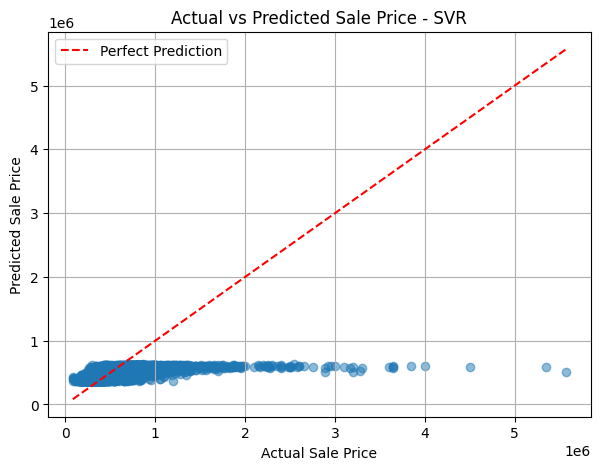

In [103]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_svr, alpha=0.5)

min_value = min(y_test.min(), y_pred_svr.min())
max_value = max(y_test.max(), y_pred_svr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - SVR")
plt.legend()
plt.grid(True)

plt.show()

In [104]:
#Random Forest Regression

In [105]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully.")

Random Forest Regression model trained successfully.


In [107]:
y_pred_rf = rf_model.predict(X_test)

print(y_pred_rf[:5])

[ 401871.26095238  633731.          961579.25       2259919.39072341
  823112.        ]


In [108]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("-------------------------")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Regression
-------------------------
MAE : 162898.39705015643
MSE : 73332814102.53578
RMSE: 270800.3214594395
R²  : 0.5154300662138587


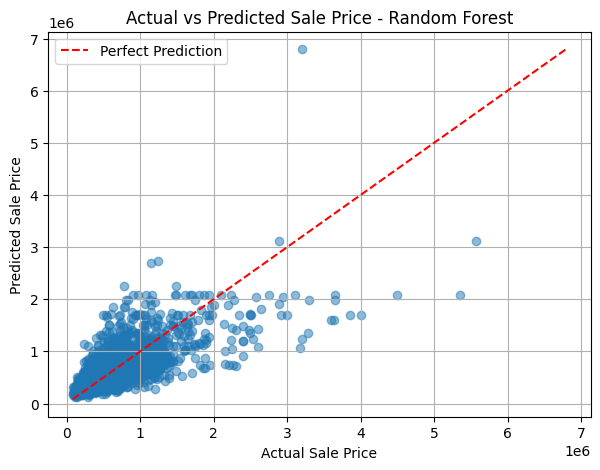

In [109]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_rf, alpha=0.5)

min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - Random Forest")
plt.legend()
plt.grid(True)

plt.show()

In [110]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "KNN Regressor",
        "SVR",
        "Random Forest Regressor"
    ],

    "MAE": [
        mae_lr,
        mae_knn,
        mae_svr,
        mae_rf
    ],

    "MSE": [
        mse_lr,
        mse_knn,
        mse_svr,
        mse_rf
    ],

    "RMSE": [
        rmse_lr,
        rmse_knn,
        rmse_svr,
        rmse_rf
    ],

    "R2 Score": [
        r2_lr,
        r2_knn,
        r2_svr,
        r2_rf
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,169941.688315,8.417138e+10,290123.035424,0.443811
1,KNN Regressor,163899.492528,7.012737e+10,264815.734428,0.536611
2,SVR,192946.117363,1.286086e+11,358620.347531,0.150178
3,Random Forest Regressor,162898.397050,7.333281e+10,270800.321459,0.515430


In [111]:

results.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,MSE,RMSE,R2 Score
1,KNN Regressor,163899.492528,7.012737e+10,264815.734428,0.536611
3,Random Forest Regressor,162898.397050,7.333281e+10,270800.321459,0.515430
0,Linear Regression,169941.688315,8.417138e+10,290123.035424,0.443811
2,SVR,192946.117363,1.286086e+11,358620.347531,0.150178


In [112]:
joblib.dump(knn_model, "best_knn_regressor.pkl")

print("KNN Regressor saved successfully.")

KNN Regressor saved successfully.


In [113]:
joblib.dump(scaler, "knn_scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


In [114]:
import joblib

knn_model = joblib.load("best_knn_regressor.pkl")
scaler = joblib.load("knn_scaler.pkl")

print("Model and scaler loaded successfully.")

Model and scaler loaded successfully.


In [115]:
new_house = pd.DataFrame({
    "No of Bedrooms": [3],
    "No of Bathrooms": [2.0],
    "Flat Area (in Sqft)": [1800],
    "Overall Grade": [7],
    "Area of the House from Basement (in Sqft)": [1000]
})

new_house

,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Overall Grade,Area of the House from Basement (in Sqft)
0,3,2.0,1800,7,1000


In [116]:
new_house_scaled = scaler.transform(new_house)

In [117]:
predicted_price = knn_model.predict(new_house_scaled)

print("Predicted Sale Price:", predicted_price[0])

Predicted Sale Price: 636600.0


**Conclusion**
-Among the four regression models, KNN Regressor performs the best overall based on the highest R² score of 0.5366.
It also has the lowest MSE and lowest RMSE mong the models.
Random Forest has a slightly lower MAE than KNN, but its R² is lower at 0.5154.
Linear Regression performs moderately, while SVR performs the weakest.
Therefore, KNN Regressor is selected as the best baseline model for predicting Sale Price.